<img src="https://www.pucsp.br/sites/default/files/download/brasao-PUCSP-assinatura-principal-RGB.png" style="float:right;" width="150px">

# IA ML Atividade — Random Forest com Scikit-Learn

**Ciência da Computação · Inteligência Artificial · PUC-SP**

| | |
|---|---|
| **Dupla** | Rubens Rodrigues Maranesi / Pedro Gabriel takenobu Serafim |
| **Conjunto de dados (Vega Datasets)** | `cars` — 406 carros (1970–1982) com consumo, potência, peso, cilindrada e país de origem |

Este notebook resolve os 10 itens do LAB da aula *PUCSP_CS_AI_11_AI_ML_RandomForest*:

| # | Item do LAB | Seção |
|---|---|---|
| 1 | Você sobreviveria ao Titanic? | [Parte A.5](#A5) |
| 2 | Estatística descritiva / interpolação para preencher `Age` | [Parte A.2](#A2) |
| 3 | Limpar melhor os dados do Titanic | [Parte A.3](#A3) |
| 4 | Usar `titanic/test.csv` e verificar a acurácia | [Parte A.4](#A4) |
| 5 | Outro conjunto de dados do Vega Dataset com Random Forest | [Parte B.1–B.2](#B1) |
| 6 | Explicar IA, ML e Random Forest (pairing) | [Parte C.1](#C1) |
| 7 | Experimentar regressão | [Parte B.3](#B3) |
| 8 | Elaborar visualizações | ao longo do notebook (+ [B.4](#B4)) |
| 9 | Analisar e entender o gráfico do Random Forest | [Parte B.5](#B5) |
| 10 | Prós e contras: Decision Tree × Random Forest | [Parte C.2](#C2) |

## 0. Preparação do ambiente

In [ ]:
# No Google Colab, descomente a linha abaixo na primeira execução
!pip install -q vega_datasets missingno kagglehub

In [ ]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from vega_datasets import data

from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold,
                                     cross_val_score, GridSearchCV)
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, mean_absolute_error,
                             mean_squared_error, r2_score)
from sklearn.inspection import permutation_importance, DecisionBoundaryDisplay

SEED = 42
pd.set_option("display.max_columns", 30)

# Paleta categórica fixa (mesma cor = mesma categoria em todos os gráficos)
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"   # azul, laranja, verde-água
GRAY = "#8a8985"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})

---
# Parte A — Titanic

## A.1 Importar os dados

Igual à aula: baixamos os arquivos da competição com o `kagglehub` (no Colab a chave fica em *Secrets* como `KAGGLE_API_TOKEN`).
Se o download do Kaggle falhar (sem chave, por exemplo), usamos uma cópia pública dos **mesmos** `train.csv` e `test.csv` hospedada no GitHub.

In [ ]:
os.makedirs("titanic", exist_ok=True)
try:
    import kagglehub
    kagglehub.competition_download("titanic", output_dir="titanic")
    print("Dados baixados do Kaggle")
except Exception as e:
    print("Kaggle indisponível (", type(e).__name__, ") -> usando espelho do GitHub")
    base = "https://raw.githubusercontent.com/agconti/kaggle-titanic/master/data/"
    for f in ["train.csv", "test.csv"]:
        pd.read_csv(base + f).to_csv(f"titanic/{f}", index=False)

train_raw = pd.read_csv("titanic/train.csv")
test_raw = pd.read_csv("titanic/test.csv")
print("train:", train_raw.shape, "| test:", test_raw.shape)
train_raw.head()

Kaggle indisponível ( UnauthenticatedError ) -> usando espelho do GitHub
train: (891, 12) | test: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
faltantes = pd.DataFrame({
    "train (nulos)": train_raw.isna().sum(),
    "test (nulos)": test_raw.isna().sum(),
})
faltantes[faltantes.sum(axis=1) > 0]

,train (nulos),test (nulos)
Age,177,86.0
Cabin,687,327.0
Embarked,2,0.0
Fare,0,1.0


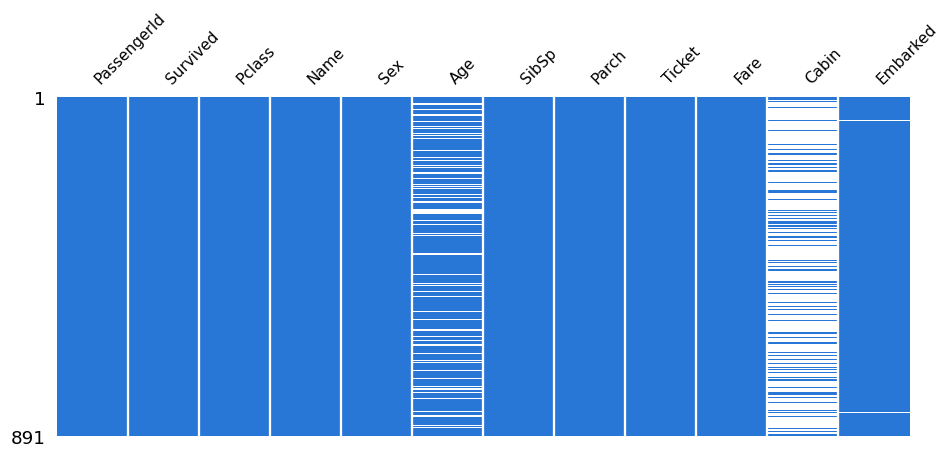

In [ ]:
msno.matrix(train_raw, figsize=(10, 4), fontsize=10, sparkline=False, color=(0.16, 0.47, 0.84));

**Leitura:** `Age` tem 177 nulos (~20%), `Cabin` ~77% e `Embarked` só 2. No `test.csv` ainda falta 1 `Fare`.

<a id="A2"></a>
## A.2 Item 2 — Estatística descritiva para preencher `Age`

Comparamos várias formas de preencher a idade, **mantendo o mesmo modelo da aula** (`Pclass`, `Sex`, `Age`) para que a única diferença seja o preenchimento.

Para a comparação ser justa, a estatística (média, mediana…) é calculada **só na parte de treino de cada fold** da validação cruzada e aplicada na parte de validação — senão o modelo "espia" a resposta.

In [ ]:
def extrair_titulo(nome):
    t = nome.split(",")[1].split(".")[0].strip()
    mapa = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs", "Lady": "Rare", "Countess": "Rare",
            "the Countess": "Rare", "Capt": "Rare", "Col": "Rare", "Don": "Rare", "Dona": "Rare",
            "Dr": "Rare", "Major": "Rare", "Rev": "Rare", "Sir": "Rare", "Jonkheer": "Rare"}
    return mapa.get(t, t)

def preencher_idade(treino, alvo, estrategia):
    # Preenche Age de `alvo` usando estatísticas aprendidas em `treino`
    alvo = alvo.copy()
    idade = alvo["Age"]
    if estrategia == "média":
        alvo["Age"] = idade.fillna(treino["Age"].mean())
    elif estrategia == "mediana":
        alvo["Age"] = idade.fillna(treino["Age"].median())
    elif estrategia == "moda":
        alvo["Age"] = idade.fillna(treino["Age"].mode()[0])
    elif estrategia == "média ± std (aleatório)":
        rng = np.random.default_rng(SEED)
        m, s = treino["Age"].mean(), treino["Age"].std()
        sorteio = rng.uniform(max(m - s, 0.5), m + s, size=idade.isna().sum())
        alvo.loc[idade.isna(), "Age"] = sorteio
    elif estrategia == "média por sexo (aula)":
        med = treino.groupby("Sex")["Age"].mean()
        alvo["Age"] = idade.fillna(alvo["Sex"].map(med))
    elif estrategia == "mediana por sexo e classe":
        med = treino.groupby(["Sex", "Pclass"])["Age"].median()
        chave = pd.MultiIndex.from_frame(alvo[["Sex", "Pclass"]])
        alvo["Age"] = idade.fillna(pd.Series(med.reindex(chave).values, index=alvo.index))
    elif estrategia == "mediana por título (Mr, Mrs, Miss, Master)":
        tit_tr = treino["Name"].map(extrair_titulo)
        tit_al = alvo["Name"].map(extrair_titulo)
        med = treino["Age"].groupby(tit_tr).median()
        alvo["Age"] = idade.fillna(tit_al.map(med)).fillna(treino["Age"].median())
    elif estrategia == "interpolação linear":
        # interpola na ordem das linhas (PassengerId) — não usa o alvo
        alvo["Age"] = idade.interpolate(limit_direction="both")
    return alvo

def X_aula(df):
    return pd.DataFrame({"Pclass": df["Pclass"],
                         "SexNumber": df["Sex"].map({"male": 100, "female": 200}),
                         "Age": df["Age"]})

estrategias = ["média", "mediana", "moda", "média ± std (aleatório)", "média por sexo (aula)",
               "mediana por sexo e classe", "mediana por título (Mr, Mrs, Miss, Master)",
               "interpolação linear"]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
y = train_raw["Survived"]
resultados = []
for est in estrategias:
    accs = []
    for i_tr, i_va in skf.split(train_raw, y):
        tr, va = train_raw.iloc[i_tr], train_raw.iloc[i_va]
        tr_f, va_f = preencher_idade(tr, tr, est), preencher_idade(tr, va, est)
        rf = RandomForestClassifier(n_estimators=200, random_state=SEED)
        rf.fit(X_aula(tr_f), y.iloc[i_tr])
        accs.append(accuracy_score(y.iloc[i_va], rf.predict(X_aula(va_f))))
    resultados.append({"estratégia": est, "acurácia média (CV 5)": np.mean(accs), "desvio": np.std(accs)})

res_idade = pd.DataFrame(resultados).sort_values("acurácia média (CV 5)", ascending=False)
res_idade.style.format({"acurácia média (CV 5)": "{:.3f}", "desvio": "{:.3f}"}).hide(axis="index")

estratégia,acurácia média (CV 5),desvio
média por sexo (aula),0.797,0.038
mediana,0.797,0.038
moda,0.795,0.036
média,0.793,0.037
mediana por sexo e classe,0.793,0.035
"mediana por título (Mr, Mrs, Miss, Master)",0.792,0.032
média ± std (aleatório),0.777,0.032
interpolação linear,0.773,0.045


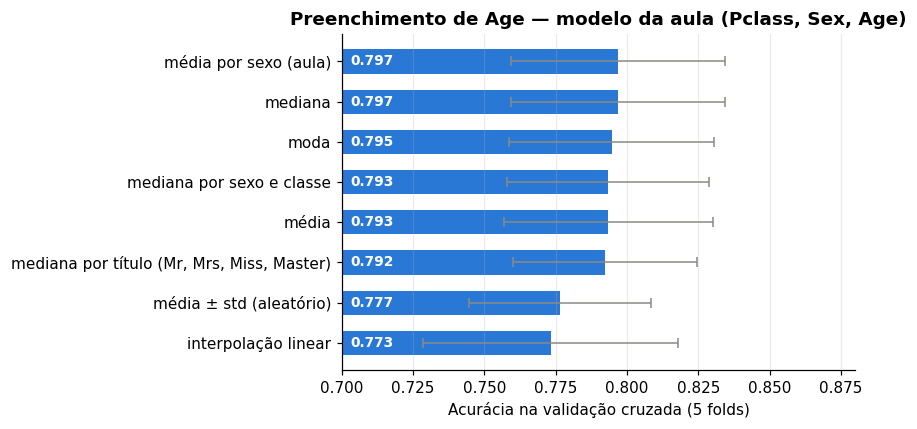

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
r = res_idade.sort_values("acurácia média (CV 5)")
ax.barh(r["estratégia"], r["acurácia média (CV 5)"], xerr=r["desvio"], color=C1,
        height=0.6, error_kw=dict(ecolor=GRAY, lw=1, capsize=3))
for i, v in enumerate(r["acurácia média (CV 5)"]):
    ax.text(0.703, i, f"{v:.3f}", va="center", fontsize=9, color="white", fontweight="bold")
ax.set_xlim(0.70, 0.88)
ax.set_xlabel("Acurácia na validação cruzada (5 folds)")
ax.set_title("Preenchimento de Age — modelo da aula (Pclass, Sex, Age)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

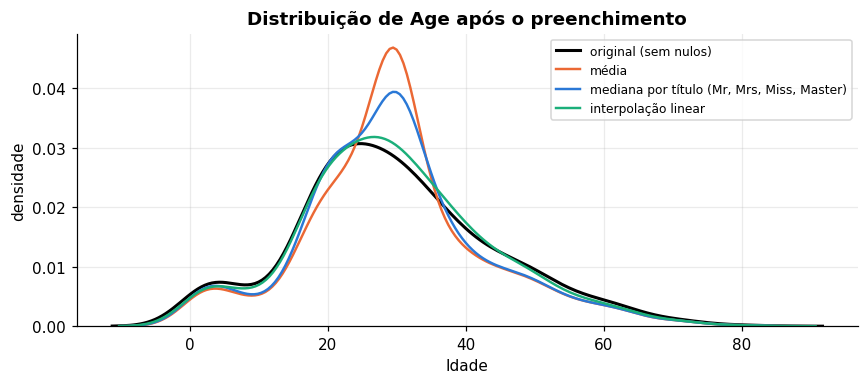

In [ ]:
# Como cada estratégia altera a distribuição de idades
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.kdeplot(train_raw["Age"].dropna(), ax=ax, color="black", lw=2, label="original (sem nulos)")
for est, cor in [("média", C2), ("mediana por título (Mr, Mrs, Miss, Master)", C1),
                 ("interpolação linear", C3)]:
    sns.kdeplot(preencher_idade(train_raw, train_raw, est)["Age"], ax=ax, color=cor, lw=1.6, label=est)
ax.set_xlabel("Idade"); ax.set_ylabel("densidade"); ax.legend(fontsize=8)
ax.set_title("Distribuição de Age após o preenchimento")
plt.tight_layout(); plt.show()

**Conclusões do item 2**

- Preencher com um valor estatístico (média, mediana, moda, ou por grupo) dá praticamente o mesmo resultado (~0,79–0,80) — as diferenças ficam dentro do desvio entre folds. Com só `Pclass`, `Sex` e `Age`, quem mais decide é o **sexo** e a **classe**.
- Sortear idades (média ± std) ou interpolar **piora** (~0,77): inserem idades aleatórias, ou seja, ruído.
- Preencher com um **único valor** (média, mediana, moda) cria um pico artificial na distribuição (curva laranja) — 177 pessoas passam a ter exatamente ~29 anos.
- A **mediana por título** não se destaca neste modelo de 3 features, mas é a mais sensata: `Master` indica menino, `Miss` costuma ser mais jovem que `Mrs`. Ela preserva melhor o formato original (curva azul) e será usada na limpeza do item 3, junto com o próprio título como feature.
- A **interpolação** não faz muito sentido aqui: as linhas não têm ordem natural (não é série temporal), então ela só "copia" idades de passageiros vizinhos na lista.

<a id="A3"></a>
## A.3 Item 3 — Limpar melhor os dados

Problemas encontrados no tratamento feito em aula:

1. `titanic_df.fillna(29, inplace=True)` preenche **todas** as colunas com 29 — `Cabin` vira `29` e `Embarked` vira `29`.
2. Multiplicar por 10 as idades menores que 1 transforma bebês de 5 meses em crianças de 4 anos. Pelo dicionário de dados, idade fracionária < 1 **é válida** (são bebês) — não é erro.
3. `Sex` codificado como 100/200: funciona para árvores, mas 0/1 é mais claro.
4. O modelo foi avaliado (`score`) nos **mesmos dados do treino**, o que superestima a acurácia.

Limpeza e novas features (*feature engineering*):

| Feature | Como foi criada |
|---|---|
| `Title` | extraído do nome (Mr, Mrs, Miss, Master, Rare) |
| `Age` | mediana por título (aprendida no treino) |
| `FamilySize`, `IsAlone` | `SibSp + Parch + 1` |
| `Fare` | nulo → mediana da classe; usamos `log(1+Fare)` |
| `HasCabin`, `Deck` | se tem cabine registrada e a letra do deck |
| `Embarked` | 2 nulos → porto mais comum (S) |

In [ ]:
class LimpadorTitanic:
    # Aprende as estatísticas no treino (fit) e aplica em qualquer conjunto (transform)
    def fit(self, df):
        tit = df["Name"].map(extrair_titulo)
        self.idade_titulo = df["Age"].groupby(tit).median()
        self.idade_geral = df["Age"].median()
        self.fare_classe = df.groupby("Pclass")["Fare"].median()
        self.embarked_moda = df["Embarked"].mode()[0]
        return self

    def transform(self, df):
        out = pd.DataFrame(index=df.index)
        tit = df["Name"].map(extrair_titulo)
        out["Pclass"] = df["Pclass"]
        out["Sex"] = (df["Sex"] == "female").astype(int)          # 1 = mulher
        out["Age"] = df["Age"].fillna(tit.map(self.idade_titulo)).fillna(self.idade_geral)
        out["SibSp"], out["Parch"] = df["SibSp"], df["Parch"]
        out["FamilySize"] = df["SibSp"] + df["Parch"] + 1
        out["IsAlone"] = (out["FamilySize"] == 1).astype(int)
        fare = df["Fare"].fillna(df["Pclass"].map(self.fare_classe))
        out["LogFare"] = np.log1p(fare)
        out["HasCabin"] = df["Cabin"].notna().astype(int)
        deck = df["Cabin"].str[0].fillna("U")
        for d in ["A", "B", "C", "D", "E", "F"]:
            out[f"Deck_{d}"] = (deck == d).astype(int)
        emb = df["Embarked"].fillna(self.embarked_moda)
        for p in ["C", "Q", "S"]:
            out[f"Emb_{p}"] = (emb == p).astype(int)
        for t in ["Mr", "Mrs", "Miss", "Master", "Rare"]:
            out[f"Title_{t}"] = (tit == t).astype(int)
        return out

limpador = LimpadorTitanic().fit(train_raw)
X_full = limpador.transform(train_raw)
print("Nulos restantes:", X_full.isna().sum().sum())
X_full.head()

Nulos restantes: 0


,Pclass,Sex,Age,SibSp,Parch,FamilySize,IsAlone,LogFare,HasCabin,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Emb_C,Emb_Q,Emb_S,Title_Mr,Title_Mrs,Title_Miss,Title_Master,Title_Rare
0,3,0,22.0,1,0,2,0,2.110213,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0
1,1,1,38.0,1,0,2,0,4.280593,1,0,0,1,0,0,0,1,0,0,0,1,0,0,0
2,3,1,26.0,0,0,1,1,2.188856,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0
3,1,1,35.0,1,0,2,0,3.990834,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0
4,3,0,35.0,0,0,1,1,2.202765,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0


In [ ]:
# Comparação justa: limpeza aprendida dentro de cada fold
def cv_titanic(modelo, transformar, n_splits=5):
    accs = []
    for i_tr, i_va in StratifiedKFold(n_splits, shuffle=True, random_state=SEED).split(train_raw, y):
        tr, va = train_raw.iloc[i_tr], train_raw.iloc[i_va]
        Xtr, Xva = transformar(tr, tr), transformar(tr, va)
        modelo.fit(Xtr, y.iloc[i_tr])
        accs.append(accuracy_score(y.iloc[i_va], modelo.predict(Xva)))
    return np.mean(accs), np.std(accs)

aula = lambda tr, al: X_aula(preencher_idade(tr, al, "média por sexo (aula)"))
limpo = lambda tr, al: LimpadorTitanic().fit(tr).transform(al)

rf_padrao = RandomForestClassifier(random_state=SEED)
comparacao = {
    "Aula: Pclass+Sex+Age, RF padrão": cv_titanic(rf_padrao, aula),
    "Limpo + features, RF padrão": cv_titanic(RandomForestClassifier(random_state=SEED), limpo),
}
for k, (m, s) in comparacao.items():
    print(f"{k:40s} {m:.3f} ± {s:.3f}")

Aula: Pclass+Sex+Age, RF padrão          0.792 ± 0.041
Limpo + features, RF padrão              0.807 ± 0.009


O Random Forest padrão deixa as árvores crescerem até decorar o treino (overfitting). Vamos ajustar os **hiperparâmetros** com `GridSearchCV`:

In [ ]:
grid = GridSearchCV(
    RandomForestClassifier(random_state=SEED, n_jobs=-1),
    param_grid={"n_estimators": [300],
                "max_depth": [4, 6, 8, None],
                "min_samples_leaf": [1, 2, 4],
                "max_features": ["sqrt", 0.5]},
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="accuracy", n_jobs=-1)
grid.fit(X_full, y)
melhores = grid.best_params_
print("Melhores hiperparâmetros:", melhores)
print(f"Acurácia CV: {grid.best_score_:.3f}")

rf_ajustado = RandomForestClassifier(random_state=SEED, n_jobs=-1, **melhores)
comparacao["Limpo + features, RF ajustado"] = cv_titanic(rf_ajustado, limpo)

Melhores hiperparâmetros: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 4, 'n_estimators': 300}
Acurácia CV: 0.839


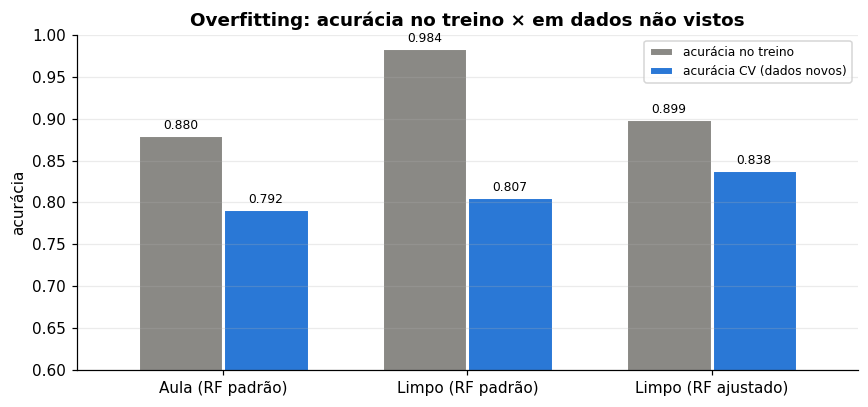

,acurácia no treino,acurácia CV (dados novos)
modelo,,
Aula (RF padrão),0.880,0.792
Limpo (RF padrão),0.984,0.807
Limpo (RF ajustado),0.899,0.838


In [ ]:
# Treino × validação: o "score" da aula estava medindo o treino
linhas = []
for nome, transf, modelo in [("Aula (RF padrão)", aula, RandomForestClassifier(random_state=SEED)),
                             ("Limpo (RF padrão)", limpo, RandomForestClassifier(random_state=SEED)),
                             ("Limpo (RF ajustado)", limpo, RandomForestClassifier(random_state=SEED, **melhores))]:
    Xa = transf(train_raw, train_raw)
    acc_treino = modelo.fit(Xa, y).score(Xa, y)
    m, s = cv_titanic(modelo, transf)
    linhas.append({"modelo": nome, "acurácia no treino": acc_treino, "acurácia CV (dados novos)": m})
tab = pd.DataFrame(linhas).set_index("modelo")

ax = tab.plot.bar(figsize=(8, 3.8), color=[GRAY, C1], width=0.7, rot=0, edgecolor="white", linewidth=2)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8, padding=2)
ax.set_ylim(0.6, 1.0); ax.set_ylabel("acurácia"); ax.set_xlabel("")
ax.set_title("Overfitting: acurácia no treino × em dados não vistos")
ax.legend(loc="upper right", fontsize=8); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
tab.round(3)

**Conclusões do item 3**

- A limpeza corrigiu os erros (`Cabin`/`Embarked` = 29, bebês "envelhecidos") e trouxe informações novas: título, família, tarifa, cabine e porto.
- O RF padrão chega a ~98% no treino, mas bem menos em dados novos → **overfitting**. Limitar a profundidade (`max_depth`) e o tamanho mínimo das folhas (`min_samples_leaf`) aproxima as duas medidas e melhora a generalização.

<a id="A4"></a>
## A.4 Item 4 — Dados de teste (`titanic/test.csv`) e acurácia

O `test.csv` do Kaggle **não tem a coluna `Survived`** — é o conjunto de competição; a resposta fica com o Kaggle:

In [ ]:
print("Colunas do test.csv:", list(test_raw.columns))
print("'Survived' está no test.csv?", "Survived" in test_raw.columns)

Colunas do test.csv: ['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
'Survived' está no test.csv? False


Então medimos a acurácia de duas formas:

1. **Hold-out:** separamos 20% do `train.csv` como teste (o modelo nunca vê essas linhas no treino).
2. **Kaggle:** treinamos com todo o `train.csv`, prevemos o `test.csv` e geramos `submission.csv`. Ao enviar em *kaggle.com/c/titanic → Submit Predictions*, o Kaggle devolve a acurácia oficial. (Para comparação: o arquivo `gender_submission.csv`, "todas as mulheres sobrevivem", faz ≈ 0,766.)

In [ ]:
tr_df, te_df = train_test_split(train_raw, test_size=0.2, stratify=y, random_state=SEED)
limp_ho = LimpadorTitanic().fit(tr_df)
Xtr, Xte = limp_ho.transform(tr_df), limp_ho.transform(te_df)
ytr, yte = tr_df["Survived"], te_df["Survived"]

rf_ho = RandomForestClassifier(random_state=SEED, n_jobs=-1, **melhores).fit(Xtr, ytr)
pred_ho = rf_ho.predict(Xte)
print(f"Acurácia no hold-out (179 passageiros nunca vistos): {accuracy_score(yte, pred_ho):.3f}\n")
print(classification_report(yte, pred_ho, target_names=["Morreu", "Sobreviveu"], digits=3))

Acurácia no hold-out (179 passageiros nunca vistos): 0.816

              precision    recall  f1-score   support

      Morreu      0.813     0.909     0.858       110
  Sobreviveu      0.821     0.667     0.736        69

    accuracy                          0.816       179
   macro avg      0.817     0.788     0.797       179
weighted avg      0.816     0.816     0.811       179



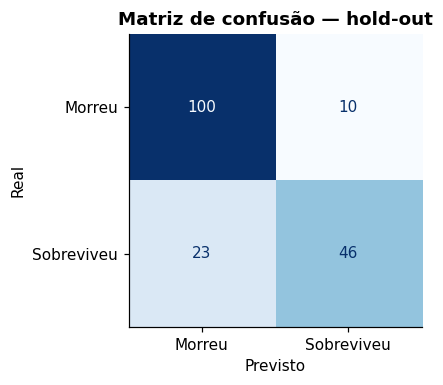

In [ ]:
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ConfusionMatrixDisplay(confusion_matrix(yte, pred_ho), display_labels=["Morreu", "Sobreviveu"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusão — hold-out"); ax.grid(False)
ax.set_xlabel("Previsto"); ax.set_ylabel("Real")
plt.tight_layout(); plt.show()

In [ ]:
# Modelo final: treina com todo o train.csv e prevê o test.csv
limpador_final = LimpadorTitanic().fit(train_raw)
rf_titanic = RandomForestClassifier(random_state=SEED, n_jobs=-1, **melhores)
rf_titanic.fit(limpador_final.transform(train_raw), y)

X_test_kaggle = limpador_final.transform(test_raw)
submission = pd.DataFrame({"PassengerId": test_raw["PassengerId"],
                           "Survived": rf_titanic.predict(X_test_kaggle)})
submission.to_csv("titanic/submission.csv", index=False)
print("Arquivo titanic/submission.csv gerado:", submission.shape)
print(f"Taxa de sobrevivência prevista no test.csv: {submission.Survived.mean():.1%} "
      f"(no treino: {y.mean():.1%})")
submission.head()

Arquivo titanic/submission.csv gerado: (418, 2)
Taxa de sobrevivência prevista no test.csv: 37.6% (no treino: 38.4%)


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


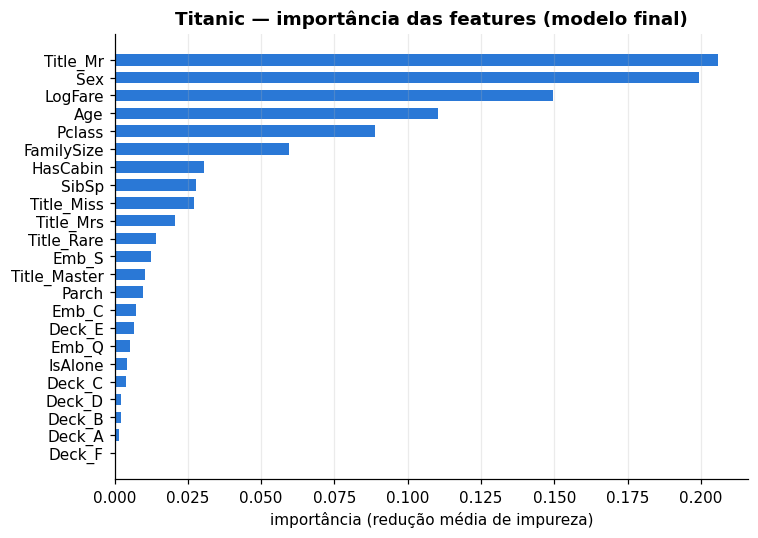

In [ ]:
imp = pd.Series(rf_titanic.feature_importances_, index=X_test_kaggle.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp.index, imp.values, color=C1, height=0.65)
ax.set_xlabel("importância (redução média de impureza)")
ax.set_title("Titanic — importância das features (modelo final)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

<a id="A5"></a>
## A.5 Item 1 — Eu sobreviveria ao Titanic?

Basta trocar os dados na célula abaixo. O modelo devolve a **probabilidade** de sobrevivência (fração das árvores que votaram "sobrevive").

In [ ]:
def eu_sobreviveria(nome_exemplo, pclass, sexo, idade, titulo, irmaos_conjuge=0, pais_filhos=0,
                    tarifa=None, embarque="S", cabine=None):
    # `titulo`: Mr, Mrs, Miss, Master ou Rare  ·  `sexo`: "male" ou "female"
    if tarifa is None:
        tarifa = train_raw.groupby("Pclass")["Fare"].median()[pclass]
    p = pd.DataFrame([{
        "PassengerId": 0, "Pclass": pclass, "Name": f"Sobrenome, {titulo}. {nome_exemplo}",
        "Sex": sexo, "Age": idade, "SibSp": irmaos_conjuge, "Parch": pais_filhos,
        "Ticket": "", "Fare": tarifa, "Cabin": cabine, "Embarked": embarque}])
    prob = rf_titanic.predict_proba(limpador_final.transform(p))[0, 1]
    veredito = "SOBREVIVERIA" if prob >= 0.5 else "não sobreviveria"
    print(f"{nome_exemplo:28s} -> {veredito:17s} (prob. de sobreviver = {prob:.0%})")
    return prob

eu_sobreviveria("Rubens Rodrigues", pclass=1, sexo="male",   idade=25, titulo="Mr")
eu_sobreviveria("Pedro Gabriel", pclass=3, sexo="male", idade=21, titulo="Mr")

# Alguns perfis para comparar
print()
eu_sobreviveria("Mulher 22 anos, 1ª classe", 1, "female", 22, "Miss", cabine="C85", embarque="C")
eu_sobreviveria("Menino 6 anos, 3ª classe, família", 3, "male", 6, "Master", 1, 2)
eu_sobreviveria("Homem 40 anos, 1ª classe", 1, "male", 40, "Mr", 1, 0, cabine="B20")
eu_sobreviveria("Homem 30 anos, 3ª classe, sozinho", 3, "male", 30, "Mr");

Rubens Rodrigues             -> não sobreviveria  (prob. de sobreviver = 30%)
Pedro Gabriel                -> não sobreviveria  (prob. de sobreviver = 6%)

Mulher 22 anos, 1ª classe    -> SOBREVIVERIA      (prob. de sobreviver = 97%)
Menino 6 anos, 3ª classe, família -> SOBREVIVERIA      (prob. de sobreviver = 84%)
Homem 40 anos, 1ª classe     -> não sobreviveria  (prob. de sobreviver = 50%)
Homem 30 anos, 3ª classe, sozinho -> não sobreviveria  (prob. de sobreviver = 5%)


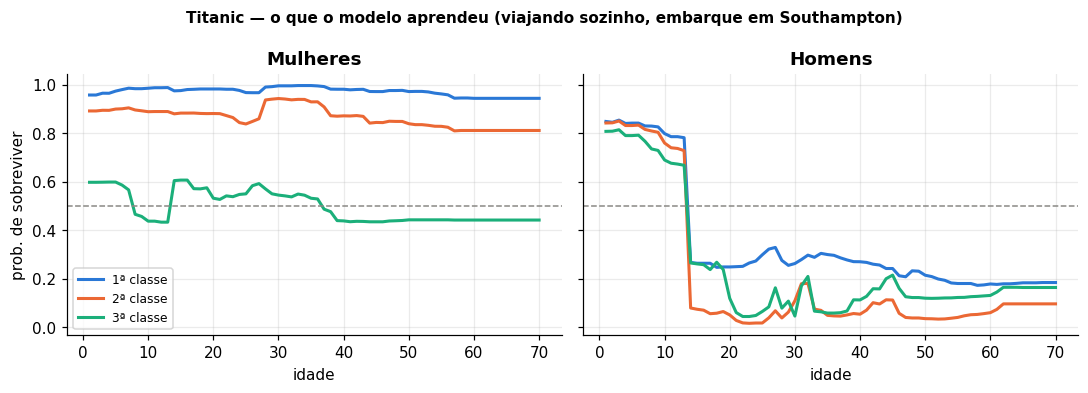

In [ ]:
# Probabilidade de sobreviver por idade, sexo e classe (o "mapa" do modelo)
idades = np.arange(1, 71)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, sexo, titulo_adulto, titulo_crianca in [(axes[0], "female", "Mrs", "Miss"),
                                                 (axes[1], "male", "Mr", "Master")]:
    for pclass, cor in [(1, C1), (2, C2), (3, C3)]:
        linhas = []
        for a in idades:
            linhas.append({"PassengerId": 0, "Pclass": pclass,
                           "Name": f"X, {titulo_crianca if a < 14 else titulo_adulto}. Y",
                           "Sex": sexo, "Age": a, "SibSp": 0, "Parch": 0, "Ticket": "",
                           "Fare": train_raw.groupby("Pclass")["Fare"].median()[pclass],
                           "Cabin": None, "Embarked": "S"})
        prob = rf_titanic.predict_proba(limpador_final.transform(pd.DataFrame(linhas)))[:, 1]
        ax.plot(idades, prob, color=cor, lw=2, label=f"{pclass}ª classe")
    ax.axhline(0.5, color=GRAY, lw=1, ls="--")
    ax.set_title("Mulheres" if sexo == "female" else "Homens")
    ax.set_xlabel("idade")
axes[0].set_ylabel("prob. de sobreviver"); axes[0].legend(fontsize=8)
fig.suptitle("Titanic — o que o modelo aprendeu (viajando sozinho, embarque em Southampton)",
             fontweight="bold", fontsize=10)
plt.tight_layout(); plt.show()

**Leitura:** "mulheres e crianças primeiro" aparece claramente. Mulheres de 1ª e 2ª classe têm alta chance; na 3ª classe a chance cai bastante. Para homens adultos a probabilidade é baixa em todas as classes — a exceção são os meninos (título *Master*).

---
<a id="B1"></a>
# Parte B — Item 5: Random Forest com o dataset `cars` (Vega Datasets)

## B.1 Conhecendo os dados

In [ ]:
cars = data.cars()
cars["Year"] = pd.to_datetime(cars["Year"]).dt.year
print(cars.shape)
cars.head()

(406, 9)


,Name,Miles_per_Gallon,Cylinders,Displacement,Horsepower,Weight_in_lbs,Acceleration,Year,Origin
0,chevrolet chevelle malibu,18.0,8,307.0,130.0,3504,12.0,1970,USA
1,buick skylark 320,15.0,8,350.0,165.0,3693,11.5,1970,USA
2,plymouth satellite,18.0,8,318.0,150.0,3436,11.0,1970,USA
3,amc rebel sst,16.0,8,304.0,150.0,3433,12.0,1970,USA
4,ford torino,17.0,8,302.0,140.0,3449,10.5,1970,USA


In [ ]:
cars.info()
cars.describe().round(1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 406 entries, 0 to 405
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Name              406 non-null    object 
 1   Miles_per_Gallon  398 non-null    float64
 2   Cylinders         406 non-null    int64  
 3   Displacement      406 non-null    float64
 4   Horsepower        400 non-null    float64
 5   Weight_in_lbs     406 non-null    int64  
 6   Acceleration      406 non-null    float64
 7   Year              406 non-null    int32  
 8   Origin            406 non-null    object 
dtypes: float64(4), int32(1), int64(2), object(2)
memory usage: 27.1+ KB


,Miles_per_Gallon,Cylinders,Displacement,Horsepower,Weight_in_lbs,Acceleration,Year
count,398.0,406.0,406.0,400.0,406.0,406.0,406.0
mean,23.5,5.5,194.8,105.1,2979.4,15.5,1976.0
std,7.8,1.7,104.9,38.8,847.0,2.8,3.9
min,9.0,3.0,68.0,46.0,1613.0,8.0,1970.0
25%,17.5,4.0,105.0,75.8,2226.5,13.7,1973.0
50%,23.0,4.0,151.0,95.0,2822.5,15.5,1976.0
75%,29.0,8.0,302.0,130.0,3618.2,17.2,1979.0
max,46.6,8.0,455.0,230.0,5140.0,24.8,1982.0


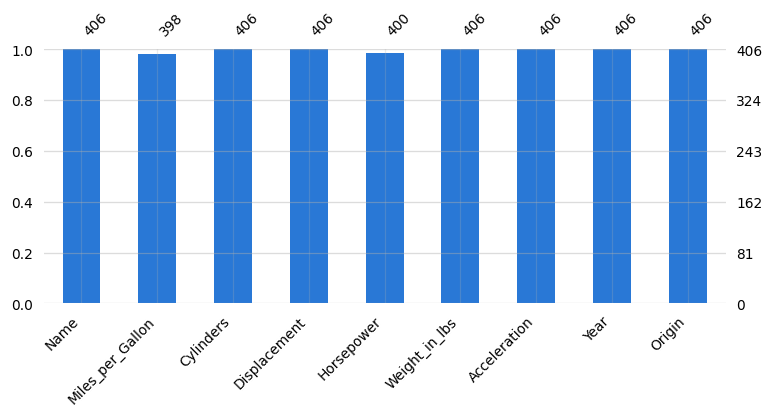

In [ ]:
msno.bar(cars, figsize=(8, 3), fontsize=9, color=(0.16, 0.47, 0.84));

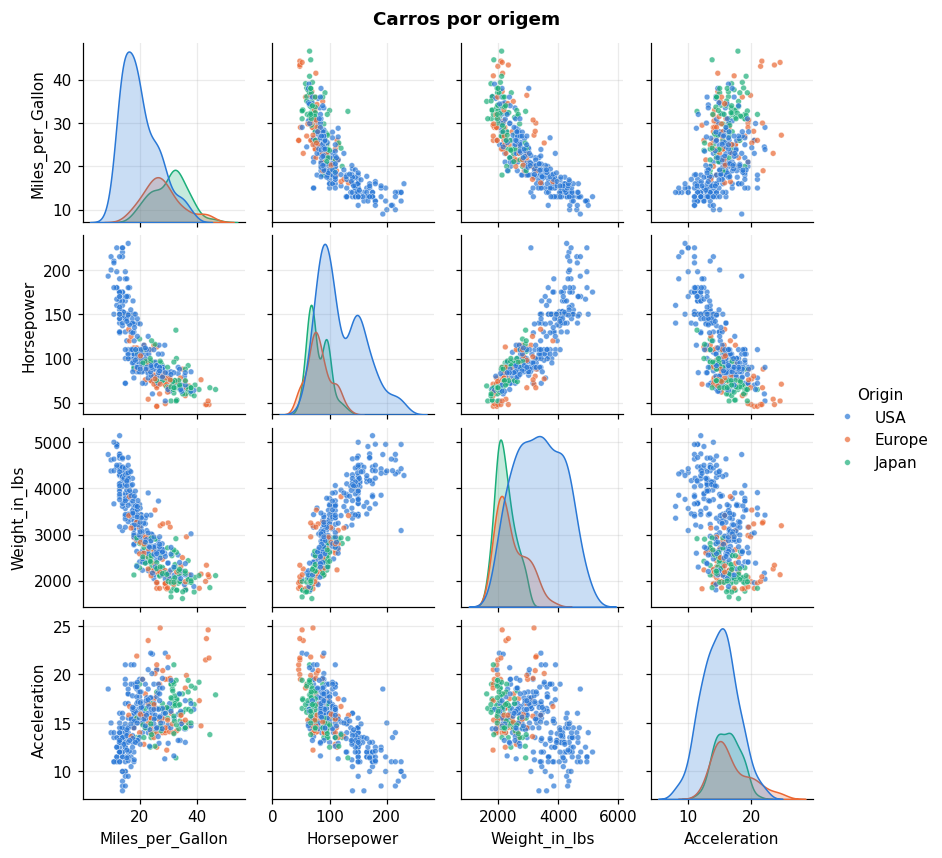

In [ ]:
CORES_ORIGEM = {"USA": C1, "Europe": C2, "Japan": C3}
g = sns.pairplot(cars, vars=["Miles_per_Gallon", "Horsepower", "Weight_in_lbs", "Acceleration"],
                 hue="Origin", palette=CORES_ORIGEM, height=1.9,
                 plot_kws=dict(s=14, alpha=0.7, linewidth=0.3, edgecolor="white"))
g.figure.suptitle("Carros por origem", y=1.02, fontweight="bold");

**Limpeza:** 8 carros sem consumo (`Miles_per_Gallon`) e 6 sem potência (`Horsepower`). Para a classificação preenchemos a potência com a **mediana por número de cilindros** (carros com o mesmo motor têm potência parecida). Na regressão o consumo é o alvo, então removemos as 8 linhas sem ele.

In [ ]:
cars["Horsepower"] = cars["Horsepower"].fillna(
    cars.groupby("Cylinders")["Horsepower"].transform("median"))
FEATS_CLS = ["Cylinders", "Displacement", "Horsepower", "Weight_in_lbs", "Acceleration", "Year"]
print("Nulos nas features:", cars[FEATS_CLS].isna().sum().sum())

Nulos nas features: 0


## B.2 Classificação — de onde vem o carro? (USA, Europe ou Japan)

Usamos as características técnicas para prever a **origem**. O consumo fica de fora porque será o alvo da regressão.

In [ ]:
Xc, yc = cars[FEATS_CLS], cars["Origin"]
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.25, stratify=yc, random_state=SEED)

rf_cars = RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1).fit(Xc_tr, yc_tr)
dt_cars = DecisionTreeClassifier(random_state=SEED).fit(Xc_tr, yc_tr)

print(f"Linha de base (chutar sempre 'USA'): {(yc_te == 'USA').mean():.3f}")
print(f"Decision Tree  — acurácia teste: {dt_cars.score(Xc_te, yc_te):.3f}")
print(f"Random Forest  — acurácia teste: {rf_cars.score(Xc_te, yc_te):.3f}\n")
print(classification_report(yc_te, rf_cars.predict(Xc_te), digits=3))

Linha de base (chutar sempre 'USA'): 0.627
Decision Tree  — acurácia teste: 0.794
Random Forest  — acurácia teste: 0.863

              precision    recall  f1-score   support

      Europe      0.706     0.667     0.686        18
       Japan      0.842     0.800     0.821        20
         USA      0.909     0.938     0.923        64

    accuracy                          0.863       102
   macro avg      0.819     0.801     0.810       102
weighted avg      0.860     0.863     0.861       102



In [ ]:
# Validação cruzada: resultado mais estável que um único split
cv10 = StratifiedKFold(10, shuffle=True, random_state=SEED)
cv_dt = cross_val_score(DecisionTreeClassifier(random_state=SEED), Xc, yc, cv=cv10)
cv_rf = cross_val_score(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1), Xc, yc, cv=cv10)
print(f"Decision Tree: {cv_dt.mean():.3f} ± {cv_dt.std():.3f}")
print(f"Random Forest: {cv_rf.mean():.3f} ± {cv_rf.std():.3f}")

Decision Tree: 0.842 ± 0.072
Random Forest: 0.847 ± 0.047


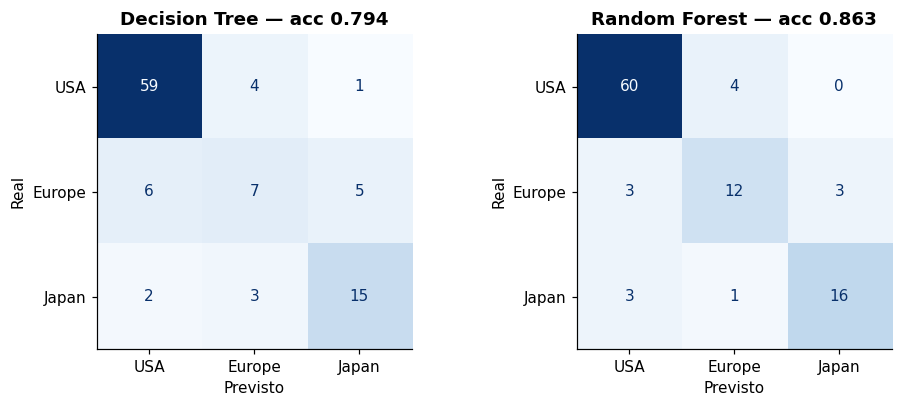

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, mod, nome in [(axes[0], dt_cars, "Decision Tree"), (axes[1], rf_cars, "Random Forest")]:
    ConfusionMatrixDisplay.from_estimator(mod, Xc_te, yc_te, ax=ax, cmap="Blues", colorbar=False,
                                          labels=["USA", "Europe", "Japan"])
    ax.set_title(f"{nome} — acc {mod.score(Xc_te, yc_te):.3f}"); ax.grid(False)
    ax.set_xlabel("Previsto"); ax.set_ylabel("Real")
plt.tight_layout(); plt.show()

**Leitura:** os carros americanos são fáceis (grandes, pesados, 8 cilindros). A confusão está entre **Europe e Japan** — ambos fazem carros pequenos e leves de 4 cilindros, com características muito parecidas.

Neste split o RF ganhou com folga (0,863 × 0,794), mas na validação cruzada de 10 folds a diferença de média é pequena (≈0,85 × 0,84); a vantagem mais clara do RF é a **estabilidade** (desvio entre folds ≈0,05 contra ≈0,07). Com só 406 carros, um único split engana — por isso usamos validação cruzada.

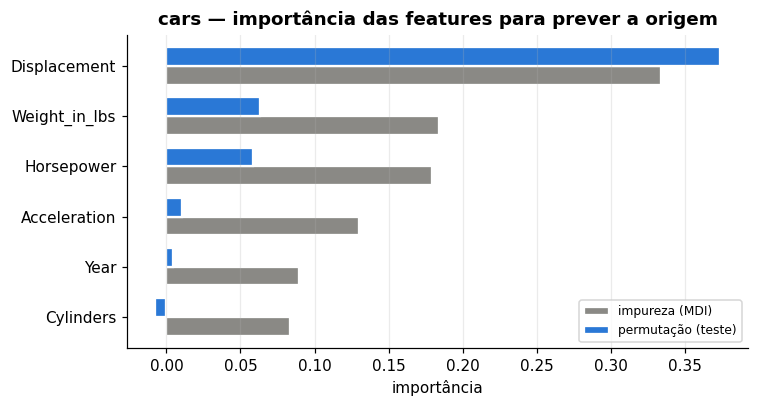

In [ ]:
# Importância das features: impureza (padrão do sklearn) × permutação (mais confiável)
perm = permutation_importance(rf_cars, Xc_te, yc_te, n_repeats=30, random_state=SEED)
imp_df = pd.DataFrame({"impureza (MDI)": rf_cars.feature_importances_,
                       "permutação (teste)": perm.importances_mean}, index=FEATS_CLS)
imp_df = imp_df.sort_values("permutação (teste)")
ax = imp_df.plot.barh(figsize=(7, 3.8), color=[GRAY, C1], width=0.75, edgecolor="white", linewidth=1.5)
ax.set_title("cars — importância das features para prever a origem")
ax.set_xlabel("importância"); ax.legend(fontsize=8); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

- **Impureza (MDI):** quanto cada feature reduziu o Gini nas divisões (soma 1). Calculada no treino; tende a favorecer features com muitos valores distintos.
- **Permutação:** quanto a acurácia **no teste** cai quando embaralhamos aquela coluna. Mede o quanto o modelo realmente depende dela.

<a id="B3"></a>
## B.3 Item 7 — Regressão: prever o consumo (milhas por galão)

Agora o alvo é um número. O `RandomForestRegressor` faz a **média** das previsões das árvores em vez de votação.

In [ ]:
cars_r = cars.dropna(subset=["Miles_per_Gallon"]).copy()
cars_r = pd.concat([cars_r, pd.get_dummies(cars_r["Origin"], prefix="Origin", dtype=int)], axis=1)
FEATS_REG = FEATS_CLS + ["Origin_USA", "Origin_Europe", "Origin_Japan"]
Xr, yr = cars_r[FEATS_REG], cars_r["Miles_per_Gallon"]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.25, random_state=SEED)

modelos_reg = {
    "Regressão Linear": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=500, random_state=SEED, n_jobs=-1),
}
linhas, previsoes = [], {}
for nome, m in modelos_reg.items():
    m.fit(Xr_tr, yr_tr)
    p = previsoes[nome] = m.predict(Xr_te)
    cv_r2 = cross_val_score(m, Xr, yr, cv=KFold(10, shuffle=True, random_state=SEED), scoring="r2")
    linhas.append({"modelo": nome, "MAE (mpg)": mean_absolute_error(yr_te, p),
                   "RMSE (mpg)": mean_squared_error(yr_te, p) ** 0.5,
                   "R² teste": r2_score(yr_te, p), "R² CV-10": cv_r2.mean()})
res_reg = pd.DataFrame(linhas).set_index("modelo")
res_reg.round(3)

,MAE (mpg),RMSE (mpg),R² teste,R² CV-10
modelo,,,,
Regressão Linear,2.331,2.961,0.846,0.815
Decision Tree,2.479,3.563,0.776,0.753
Random Forest,1.677,2.426,0.896,0.880


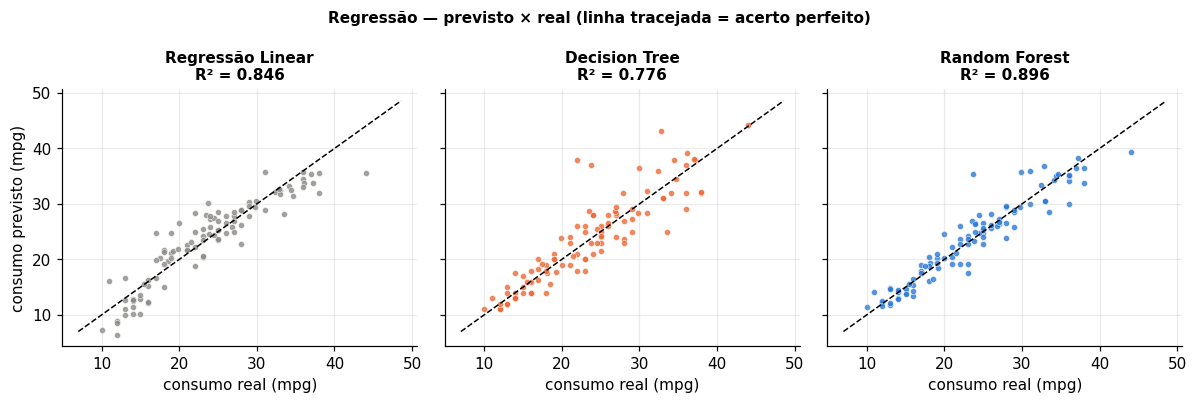

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.7), sharex=True, sharey=True)
lim = [yr.min() - 2, yr.max() + 2]
for ax, (nome, p), cor in zip(axes, previsoes.items(), [GRAY, C2, C1]):
    ax.scatter(yr_te, p, s=16, color=cor, alpha=0.8, edgecolor="white", linewidth=0.4)
    ax.plot(lim, lim, color="black", lw=1, ls="--")
    ax.set_title(f"{nome}\nR² = {r2_score(yr_te, p):.3f}", fontsize=10)
    ax.set_xlabel("consumo real (mpg)")
axes[0].set_ylabel("consumo previsto (mpg)")
fig.suptitle("Regressão — previsto × real (linha tracejada = acerto perfeito)", fontweight="bold", fontsize=10)
plt.tight_layout(); plt.show()

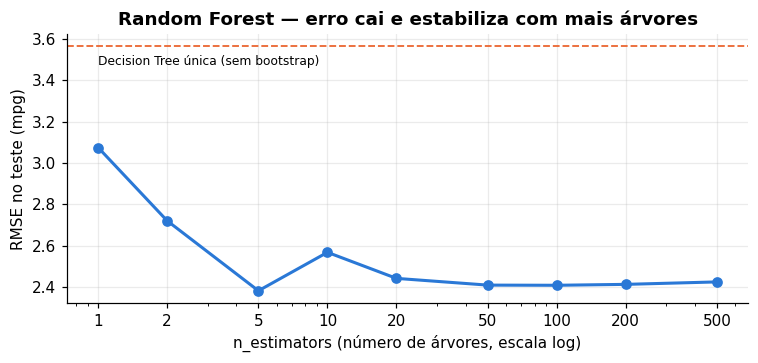

In [ ]:
# Mais árvores ajudam? (erro no teste × número de árvores)
n_arvores = [1, 2, 5, 10, 20, 50, 100, 200, 500]
rmse = [mean_squared_error(yr_te, RandomForestRegressor(n_estimators=n, random_state=SEED, n_jobs=-1)
                            .fit(Xr_tr, yr_tr).predict(Xr_te)) ** 0.5 for n in n_arvores]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(n_arvores, rmse, marker="o", color=C1, lw=2, ms=6)
ax.axhline(res_reg.loc["Decision Tree", "RMSE (mpg)"], color=C2, ls="--", lw=1.2)
ax.text(1, res_reg.loc["Decision Tree", "RMSE (mpg)"] - 0.04, "Decision Tree única (sem bootstrap)",
        color="black", ha="left", va="top", fontsize=8)
ax.set_xscale("log"); ax.set_xticks(n_arvores); ax.set_xticklabels(n_arvores)
ax.set_xlabel("n_estimators (número de árvores, escala log)"); ax.set_ylabel("RMSE no teste (mpg)")
ax.set_title("Random Forest — erro cai e estabiliza com mais árvores")
plt.tight_layout(); plt.show()

**Conclusões do item 7**

- O Random Forest erra em média ~1,7 mpg (MAE) e explica ~88–90% da variação do consumo (R²), melhor que a árvore única (R² ≈ 0,75–0,79) e a regressão linear (≈ 0,82–0,85).
- A relação peso → consumo é **curva** (pairplot): o RF captura isso sem precisar de transformações; a regressão linear não.
- O erro cai rápido nas primeiras ~20 árvores e depois estabiliza: mais árvores **não causam overfitting**, só custam mais tempo.

<a id="B4"></a>
## B.4 Item 8 — Visualização: fronteiras de decisão (Decision Tree × Random Forest)

Usando só duas features (peso e potência) dá para **ver** como cada modelo divide o plano entre USA, Europe e Japan.

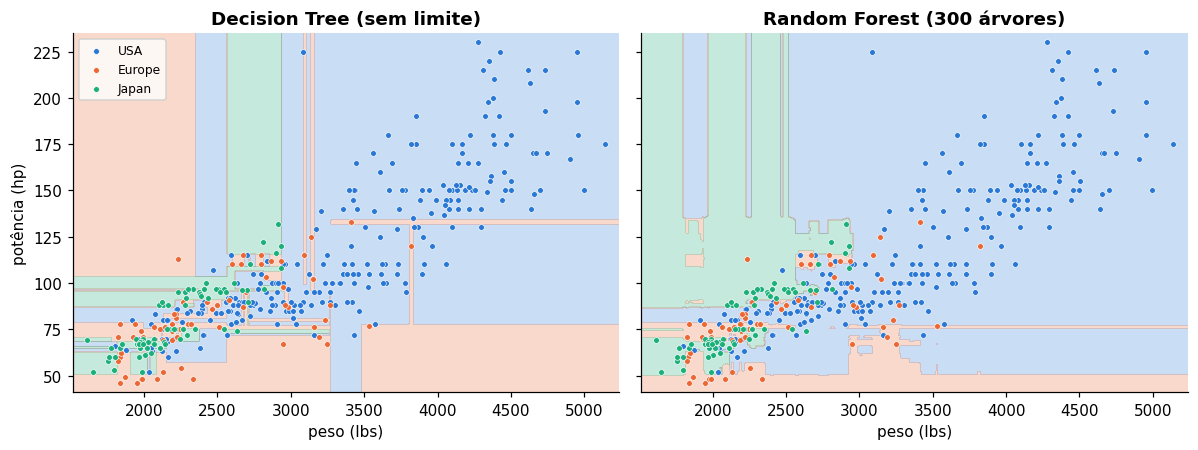

In [ ]:
from matplotlib.colors import ListedColormap
X2 = cars[["Weight_in_lbs", "Horsepower"]]
codigo = yc.map({"USA": 0, "Europe": 1, "Japan": 2})
cmap3 = ListedColormap([C1, C2, C3])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, mod, nome in [(axes[0], DecisionTreeClassifier(random_state=SEED), "Decision Tree (sem limite)"),
                      (axes[1], RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                       random_state=SEED), "Random Forest (300 árvores)")]:
    mod.fit(X2, codigo)
    xx, yy = np.meshgrid(np.linspace(X2.iloc[:, 0].min() - 100, X2.iloc[:, 0].max() + 100, 400),
                         np.linspace(X2.iloc[:, 1].min() - 5, X2.iloc[:, 1].max() + 5, 400))
    zz = mod.predict(pd.DataFrame({"Weight_in_lbs": xx.ravel(), "Horsepower": yy.ravel()})).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5, 2.5], cmap=cmap3, alpha=0.25)
    for k, (orig, cor) in enumerate(CORES_ORIGEM.items()):
        sel = codigo == k
        ax.scatter(X2.loc[sel, "Weight_in_lbs"], X2.loc[sel, "Horsepower"], s=14, color=cor,
                   edgecolor="white", linewidth=0.4, label=orig)
    ax.set_title(nome); ax.set_xlabel("peso (lbs)"); ax.set_ylabel(""); ax.grid(False)
axes[0].set_ylabel("potência (hp)"); axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

**Leitura:** a árvore única cria "ilhas" retangulares minúsculas para acertar cada ponto do treino (decorou o ruído). O Random Forest faz a média de centenas de árvores e gera regiões mais suaves e coerentes — por isso generaliza melhor.

<a id="B5"></a>
## B.5 Item 9 — Analisar e entender o gráfico do Random Forest

Um Random Forest é uma coleção de árvores. Vamos desenhar **uma** das 500 árvores do `rf_cars` (só os 3 primeiros níveis para caber na tela):

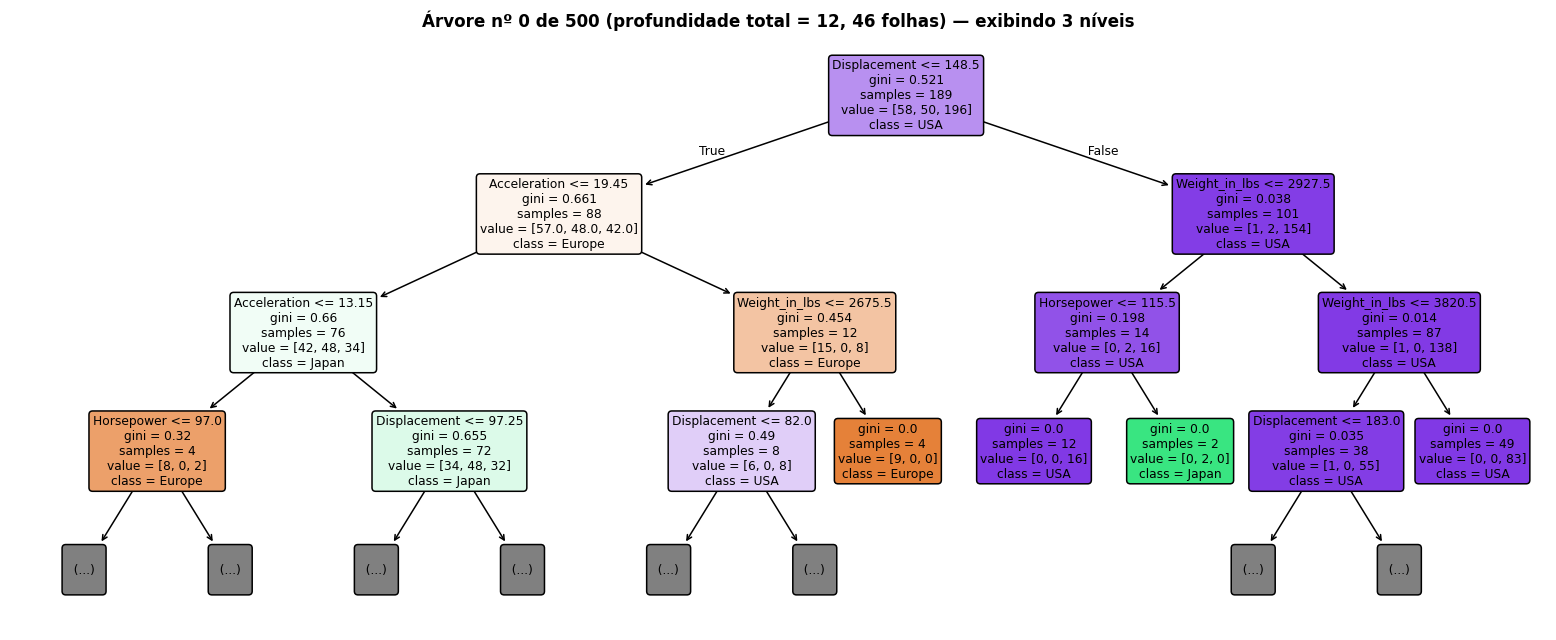

In [ ]:
arvore = rf_cars.estimators_[0]
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(arvore, max_depth=3, feature_names=FEATS_CLS, class_names=list(rf_cars.classes_),
          filled=True, rounded=True, impurity=True, proportion=False, fontsize=8, ax=ax)
ax.set_title(f"Árvore nº 0 de {len(rf_cars.estimators_)} (profundidade total = {arvore.get_depth()}, "
             f"{arvore.get_n_leaves()} folhas) — exibindo 3 níveis", fontsize=11)
plt.show()

**Como ler cada caixa (nó):**

| Linha | Significado |
|---|---|
| `Displacement <= 148.5` | a **pergunta** do nó (cilindrada). Verdadeiro → ramo da esquerda, falso → direita |
| `gini = 0.521` | **impureza**: 0 = todos da mesma classe; quanto maior, mais misturado |
| `samples = 189` | quantas amostras **distintas** chegaram ao nó (a árvore treina numa amostra *bootstrap*, com repetição) |
| `value = [58, 50, 196]` | quantas amostras de cada classe (Europe, Japan, USA), contando as repetições |
| `class = USA` | classe majoritária no nó — a cor indica a classe e a intensidade, a "certeza" (as cores aqui são as padrão do `plot_tree`: laranja = Europe, verde = Japan, roxo = USA) |

Lendo a raiz: carros com cilindrada **> 148,5** vão para a direita e são quase todos americanos (gini 0,038). Os de motor pequeno vão para a esquerda, onde Europe e Japan se misturam (gini 0,66) e a árvore precisa de muitas perguntas a mais — o mesmo ponto fraco visto na matriz de confusão.

O algoritmo escolhe, em cada nó, a pergunta que mais **reduz o Gini**. No Random Forest, cada nó só pode escolher entre um **sorteio de features** (`max_features="sqrt"` → 2 das 6), e cada árvore treina em uma amostra **bootstrap** diferente. Por isso as árvores ficam diferentes entre si:

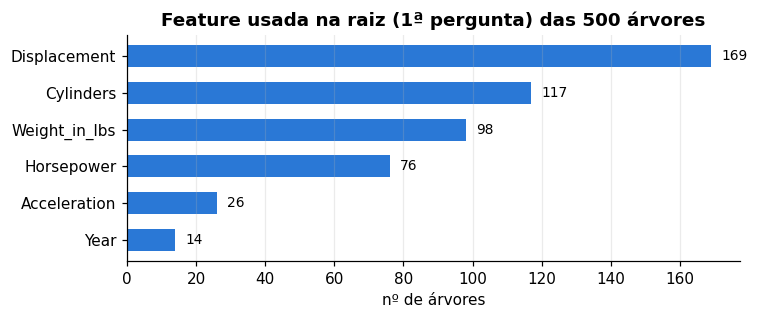

In [ ]:
raizes = pd.Series([FEATS_CLS[t.tree_.feature[0]] for t in rf_cars.estimators_]).value_counts()
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(raizes.index[::-1], raizes.values[::-1], color=C1, height=0.6)
for i, v in enumerate(raizes.values[::-1]):
    ax.text(v + 3, i, str(v), va="center", fontsize=9)
ax.set_xlabel("nº de árvores"); ax.grid(axis="y", visible=False)
ax.set_title("Feature usada na raiz (1ª pergunta) das 500 árvores")
plt.tight_layout(); plt.show()

In [ ]:
# A votação na prática: o que cada árvore "acha" de um carro do teste
carro = Xc_te.iloc[[0]]
nome_carro = cars.loc[carro.index[0], "Name"]
votos = pd.Series([rf_cars.classes_[int(t.predict(carro.values)[0])] for t in rf_cars.estimators_]).value_counts()
print(f"Carro: {nome_carro}  |  origem real: {yc_te.iloc[0]}")
display(carro)
print("Votos das 500 árvores:"); print(votos.to_string())
print("predict_proba:", dict(zip(rf_cars.classes_, rf_cars.predict_proba(carro)[0].round(3))))
print("Previsão final do Random Forest:", rf_cars.predict(carro)[0])

Carro: toyota corona mark ii  |  origem real: Japan


,Cylinders,Displacement,Horsepower,Weight_in_lbs,Acceleration,Year
20,4,113.0,95.0,2372,15.0,1970


Votos das 500 árvores:
Japan     300
Europe    188
USA        12
predict_proba: {'Europe': np.float64(0.376), 'Japan': np.float64(0.6), 'USA': np.float64(0.024)}
Previsão final do Random Forest: Japan


**Resumo do gráfico:** cada árvore sozinha é simples e erra bastante; o "segredo" do Random Forest é a **diversidade** (bootstrap + sorteio de features) seguida da **votação** (classificação) ou **média** (regressão). Os erros individuais se cancelam e a previsão coletiva fica mais estável. (O `predict_proba` do sklearn faz a média das probabilidades de cada árvore, que quase sempre coincide com a contagem de votos.)

---
<a id="C1"></a>
# Parte C — Discussão em dupla

## C.1 Item 6 — IA, ML e Random Forest

- **Inteligência Artificial (IA):** área da computação que cria sistemas capazes de realizar tarefas que exigiriam inteligência humana — reconhecer imagens, entender texto, tomar decisões, jogar xadrez.
- **Machine Learning (ML):** subárea da IA em que o computador **aprende padrões a partir de dados**, em vez de seguir regras escritas à mão. No aprendizado **supervisionado** (o desta aula) damos exemplos com a resposta certa (`X` = características, `y` = rótulo) e o modelo aprende a função `X → y` (`fit`) para depois prever casos novos (`predict`).
- **Árvore de decisão:** um fluxograma de perguntas do tipo "peso ≤ 2.900 lbs?" aprendido dos dados. Fácil de entender, mas tende a decorar o treino.
- **Random Forest:** um "comitê" de muitas árvores de decisão. Cada árvore treina com uma amostra sorteada dos dados (*bootstrap*) e, em cada nó, só olha um subconjunto sorteado de features. Na previsão, as árvores **votam** (classificação) ou têm suas respostas **promediadas** (regressão). É o princípio da "sabedoria das multidões": muitos modelos medianos e diferentes, juntos, erram menos que um só.

> Analogia: em vez de perguntar o caminho a uma única pessoa que pode estar enganada, você pergunta a 500 pessoas que conhecem partes diferentes da cidade e segue a resposta da maioria.

<a id="C2"></a>
## C.2 Item 10 — Prós e contras: Decision Tree × Random Forest

In [ ]:
import time
def tempo(m, X, y):
    t = time.perf_counter(); m.fit(X, y); return time.perf_counter() - t

resumo = pd.DataFrame({
    "Decision Tree": {
        "Titanic — acc. treino": DecisionTreeClassifier(random_state=SEED).fit(X_full, y).score(X_full, y),
        "Titanic — acc. CV-5": cross_val_score(DecisionTreeClassifier(random_state=SEED), X_full, y, cv=skf).mean(),
        "cars origem — acc. CV-10": cv_dt.mean(),
        "cars origem — desvio CV-10": cv_dt.std(),
        "cars consumo — R² CV-10": res_reg.loc["Decision Tree", "R² CV-10"],
        "tempo de treino cars (ms)": 1000 * tempo(DecisionTreeClassifier(random_state=SEED), Xc, yc),
    },
    "Random Forest": {
        "Titanic — acc. treino": RandomForestClassifier(random_state=SEED).fit(X_full, y).score(X_full, y),
        "Titanic — acc. CV-5": cross_val_score(RandomForestClassifier(random_state=SEED, **melhores), X_full, y, cv=skf).mean(),
        "cars origem — acc. CV-10": cv_rf.mean(),
        "cars origem — desvio CV-10": cv_rf.std(),
        "cars consumo — R² CV-10": res_reg.loc["Random Forest", "R² CV-10"],
        "tempo de treino cars (ms)": 1000 * tempo(RandomForestClassifier(n_estimators=300, random_state=SEED), Xc, yc),
    },
})
resumo.round(3)

,Decision Tree,Random Forest
Titanic — acc. treino,0.984,0.984
Titanic — acc. CV-5,0.781,0.839
cars origem — acc. CV-10,0.842,0.847
cars origem — desvio CV-10,0.072,0.047
cars consumo — R² CV-10,0.753,0.880
tempo de treino cars (ms),4.214,924.145


| | **Decision Tree** | **Random Forest** |
|---|---|---|
| **Interpretabilidade** | ✅ Excelente — dá para desenhar e explicar a regra inteira | ❌ Centenas de árvores: vira uma "caixa cinza" (usamos importância das features para interpretar) |
| **Precisão em dados novos** | ❌ Menor | ✅ Maior (ver tabela acima) |
| **Overfitting** | ❌ Alto se não limitar a profundidade (fronteiras com "ilhas") | ✅ Muito menor: a média das árvores reduz a variância |
| **Estabilidade** | ❌ Pequena mudança nos dados muda toda a árvore | ✅ Estável (desvio menor entre folds) |
| **Custo computacional** | ✅ Treina e prevê em milissegundos | ❌ N vezes mais lento e mais memória (paralelizável com `n_jobs=-1`) |
| **Ajuste de hiperparâmetros** | Sensível (`max_depth`, `min_samples_leaf`) | Funciona bem com os padrões; mais árvores nunca pioram |
| **Pré-processamento** | Ambos dispensam normalização e lidam com relações não lineares | Idem |
| **Extrapolação (regressão)** | ❌ Não prevê fora da faixa vista no treino | ❌ Idem |
| **Quando usar** | Precisa explicar a decisão (crédito, saúde, ensino) | Precisa de desempenho com dados tabulares e pouco ajuste |

---
## Conclusão

- **Titanic:** a limpeza (título, família, cabine, tarifa) e o ajuste de hiperparâmetros levaram o modelo de ~0,79 para ~0,84 de acurácia em validação cruzada (0,816 no hold-out), e removeram erros do tratamento original. O `test.csv` não tem rótulos, então a acurácia oficial vem do envio do `submission.csv` ao Kaggle.
- **cars (Vega):** o Random Forest identifica a origem do carro com ~85% de acerto (contra 63% chutando sempre "USA"), com resultado mais estável que uma árvore única — a confusão residual é Europa × Japão. Na regressão, prevê o consumo com R² ≈ 0,88 e erro médio de ~1,7 mpg.
- O Random Forest troca **interpretabilidade** por **precisão e estabilidade** — a diversidade das árvores e a votação/média são o que faz ele generalizar melhor.

